# Câu 2. Nhận dạng ký tự bằng Naïve Bayes và k-Nearest Neighbors

- **Dữ liệu:** UCI Letter Recognition – 20.000 mẫu, 26 lớp (A–Z), 16 đặc trưng nguyên (0–15)
- **Chia dữ liệu:** 16.000 mẫu đầu để train, 4.000 mẫu cuối để test (theo khuyến nghị của tác giả)
- Cả hai thuật toán được tự cài đặt bằng NumPy.

In [9]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

letter_dt = pd.read_csv("data/letter-recognition.data", header=None)

## 1. Đọc dữ liệu

In [10]:

# 2. Xử lý dữ liệu bằng pandas
# Cột 0 là chữ cái (A-Z) -> Chuyển thành số từ 0-25
y = df[0].apply(lambda x: ord(x) - ord('A')).to_numpy()

# Các cột còn lại (từ index 1 đến 16) là đặc trưng
X = df.iloc[:, 1:].to_numpy()

# 3. Chia tập dữ liệu Train / Test (Tự động chia theo tỷ lệ 80/20)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. In thông tin kiểm tra
print(f"Dữ liệu: {X.shape[0]} mẫu, {X.shape[1]} đặc trưng, {len(np.unique(y))} lớp")
print(f"Train: {len(Xtr)} | Test: {len(Xte)}")
print(f"Giá trị đặc trưng: {int(X.min())} -> {int(X.max())}")

Dữ liệu: 20000 mẫu, 16 đặc trưng, 26 lớp
Train: 16000 | Test: 4000
Giá trị đặc trưng: 0 -> 15


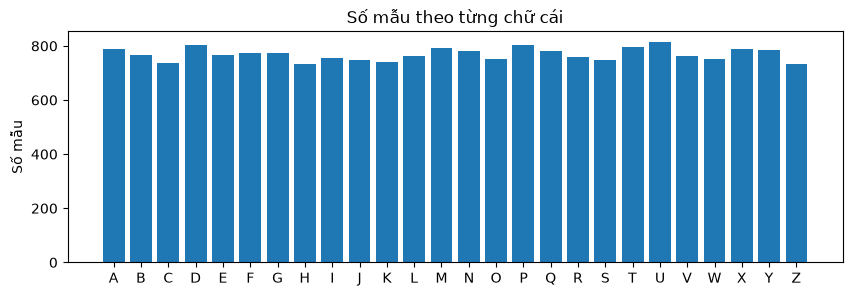

In [11]:
counts = np.bincount(y, minlength=26)
plt.figure(figsize=(10, 3))
plt.bar([chr(65+i) for i in range(26)], counts)
plt.title("Số mẫu theo từng chữ cái"); plt.ylabel("Số mẫu")
plt.show()

## 2. Naïve Bayes

Dự đoán lớp có xác suất hậu nghiệm lớn nhất, giả định các đặc trưng độc lập có điều kiện:

$$\hat c = \arg\max_c \; \log P(c) + \sum_{j=1}^{16} \log P(x_j \mid c)$$

Hai biến thể:
- **Gaussian:** $P(x_j \mid c) = \mathcal N(\mu_{cj}, \sigma_{cj}^2)$
- **Categorical:** đặc trưng nguyên 0–15 nên coi là biến rời rạc, ước lượng bằng đếm + làm mịn Laplace.

In [12]:
class GaussianNaiveBayes:
    def __init__(self, var_smoothing=1e-3):
        self.var_smoothing = var_smoothing

    def fit(self, X, y):
        self.classes = np.unique(y)
        self.prior = np.zeros(len(self.classes))
        self.mu = np.zeros((len(self.classes), X.shape[1]))
        self.var = np.zeros_like(self.mu)
        for i, c in enumerate(self.classes):
            Xc = X[y == c]
            self.prior[i] = len(Xc) / len(X)
            self.mu[i] = Xc.mean(axis=0)
            self.var[i] = Xc.var(axis=0)
        self.var += self.var_smoothing * X.var(axis=0).max()   # tránh chia cho 0
        return self

    def predict(self, X):
        diff2 = (X[:, None, :] - self.mu[None]) ** 2
        log_lik = -0.5 * (np.log(2*np.pi*self.var)[None] + diff2 / self.var[None]).sum(axis=2)
        return self.classes[np.argmax(log_lik + np.log(self.prior), axis=1)]


class CategoricalNaiveBayes:
    def __init__(self, alpha=1.0, n_values=16):
        self.alpha, self.n_values = alpha, n_values

    def fit(self, X, y):
        X = X.astype(int)
        self.classes = np.unique(y)
        C, d, V = len(self.classes), X.shape[1], self.n_values
        self.log_prior = np.zeros(C)
        self.log_lik = np.zeros((C, d, V))
        for i, c in enumerate(self.classes):
            Xc = X[y == c]
            self.log_prior[i] = np.log(len(Xc) / len(X))
            for j in range(d):
                cnt = np.bincount(Xc[:, j], minlength=V) + self.alpha   # Laplace
                self.log_lik[i, j] = np.log(cnt / cnt.sum())
        return self

    def predict(self, X):
        X = X.astype(int)
        scores = np.tile(self.log_prior, (len(X), 1))
        for i in range(len(self.classes)):
            scores[:, i] += self.log_lik[i, np.arange(X.shape[1]), X].sum(axis=1)
        return self.classes[np.argmax(scores, axis=1)]

In [13]:
def accuracy(y_true, y_pred):
    return float((y_true == y_pred).mean())

results = {}
for name, model in [("Naive Bayes (Gaussian)", GaussianNaiveBayes()),
                    ("Naive Bayes (Categorical, Laplace)", CategoricalNaiveBayes())]:
    t = time.time()
    pred = model.fit(Xtr, ytr).predict(Xte)
    results[name] = (accuracy(yte, pred), pred)
    print(f"{name:38s} accuracy = {results[name][0]*100:6.2f}%  ({time.time()-t:.2f}s)")

Naive Bayes (Gaussian)                 accuracy =  64.72%  (0.03s)
Naive Bayes (Categorical, Laplace)     accuracy =  74.25%  (0.01s)


## 3. k-Nearest Neighbors

Với mỗi mẫu cần dự đoán, tìm $k$ mẫu train gần nhất theo khoảng cách Euclid rồi bỏ phiếu đa số.
Khi hòa phiếu, ưu tiên lớp của láng giềng gần nhất.

In [14]:
class KNN:
    def __init__(self, k=3, chunk=500):
        self.k, self.chunk = k, chunk

    def fit(self, X, y):
        self.X, self.y = X, y
        self.sq = (X ** 2).sum(axis=1)
        return self

    def kneighbors_labels(self, X, kmax):
        """Nhãn của kmax láng giềng gần nhất (đã sắp theo khoảng cách)."""
        out = []
        for s in range(0, len(X), self.chunk):
            B = X[s:s+self.chunk]
            d2 = (B ** 2).sum(axis=1)[:, None] + self.sq[None] - 2 * B @ self.X.T
            idx = np.argpartition(d2, kmax, axis=1)[:, :kmax]
            order = np.argsort(np.take_along_axis(d2, idx, axis=1), axis=1)
            out.append(self.y[np.take_along_axis(idx, order, axis=1)])
        return np.vstack(out)

    @staticmethod
    def vote(neigh, k, n_classes=26):
        sub = neigh[:, :k]
        counts = np.zeros((len(sub), n_classes))
        for j in range(k):
            np.add.at(counts, (np.arange(len(sub)), sub[:, j]), 1)
        counts *= 2
        counts[np.arange(len(sub)), sub[:, 0]] += 1      # phá hòa phiếu
        return counts.argmax(axis=1)

    def predict(self, X):
        return self.vote(self.kneighbors_labels(X, self.k), self.k)

### Chọn k bằng validation
Dùng 12.000 mẫu train đầu để fit, 4.000 mẫu train cuối làm validation (không dùng tập test để chọn k).

In [15]:
ks = [1, 3, 5, 7, 9, 11, 15]
knn_val = KNN().fit(Xtr[:12000], ytr[:12000])
neigh_val = knn_val.kneighbors_labels(Xtr[12000:], max(ks))
val_acc = {k: accuracy(ytr[12000:], KNN.vote(neigh_val, k)) for k in ks}
for k in ks:
    print(f"k = {k:2d}: {val_acc[k]*100:6.2f}%")
best_k = max(val_acc, key=val_acc.get)
print("-> k tốt nhất:", best_k)

k =  1:  94.97%
k =  3:  95.17%
k =  5:  94.90%
k =  7:  94.38%
k =  9:  93.95%
k = 11:  93.30%
k = 15:  92.70%
-> k tốt nhất: 3


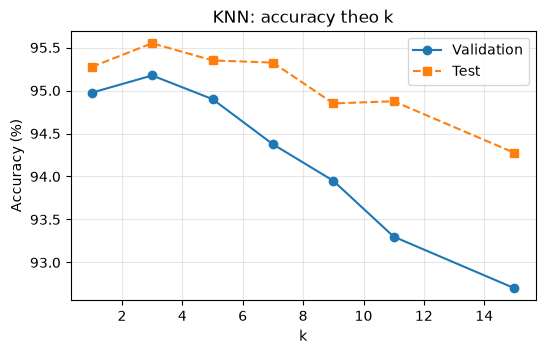

In [16]:
knn = KNN(k=best_k).fit(Xtr, ytr)
neigh_te = knn.kneighbors_labels(Xte, max(ks))
test_acc = {k: accuracy(yte, KNN.vote(neigh_te, k)) for k in ks}

plt.figure(figsize=(6, 3.5))
plt.plot(ks, [val_acc[k]*100 for k in ks], "o-", label="Validation")
plt.plot(ks, [test_acc[k]*100 for k in ks], "s--", label="Test")
plt.xlabel("k"); plt.ylabel("Accuracy (%)"); plt.legend(); plt.grid(alpha=.3)
plt.title("KNN: accuracy theo k"); plt.show()

pred_knn = KNN.vote(neigh_te, best_k)
results[f"KNN (k={best_k})"] = (accuracy(yte, pred_knn), pred_knn)

# so sánh với KNN có chuẩn hoá z-score
mu, sd = Xtr.mean(0), Xtr.std(0)
pred_z = KNN(k=best_k).fit((Xtr-mu)/sd, ytr).predict((Xte-mu)/sd)
results[f"KNN (k={best_k}, z-score)"] = (accuracy(yte, pred_z), pred_z)

## 4. So sánh kết quả

Naive Bayes (Gaussian)                  64.72%
Naive Bayes (Categorical, Laplace)      74.25%
KNN (k=3)                               95.55%
KNN (k=3, z-score)                      94.97%


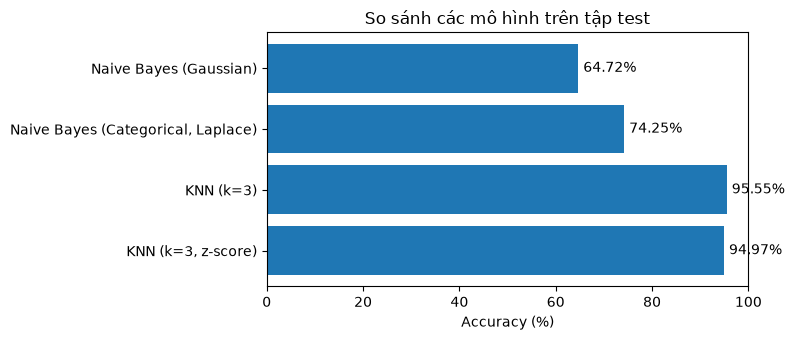

In [17]:
for name, (acc, _) in results.items():
    print(f"{name:38s} {acc*100:6.2f}%")

names = list(results); accs = [results[n][0]*100 for n in names]
plt.figure(figsize=(8, 3.5))
bars = plt.barh(names, accs)
plt.xlim(0, 100); plt.xlabel("Accuracy (%)"); plt.gca().invert_yaxis()
for b, a in zip(bars, accs):
    plt.text(a + 1, b.get_y() + b.get_height()/2, f"{a:.2f}%", va="center")
plt.title("So sánh các mô hình trên tập test"); plt.tight_layout(); plt.show()

## 5. Phân tích lỗi: ma trận nhầm lẫn

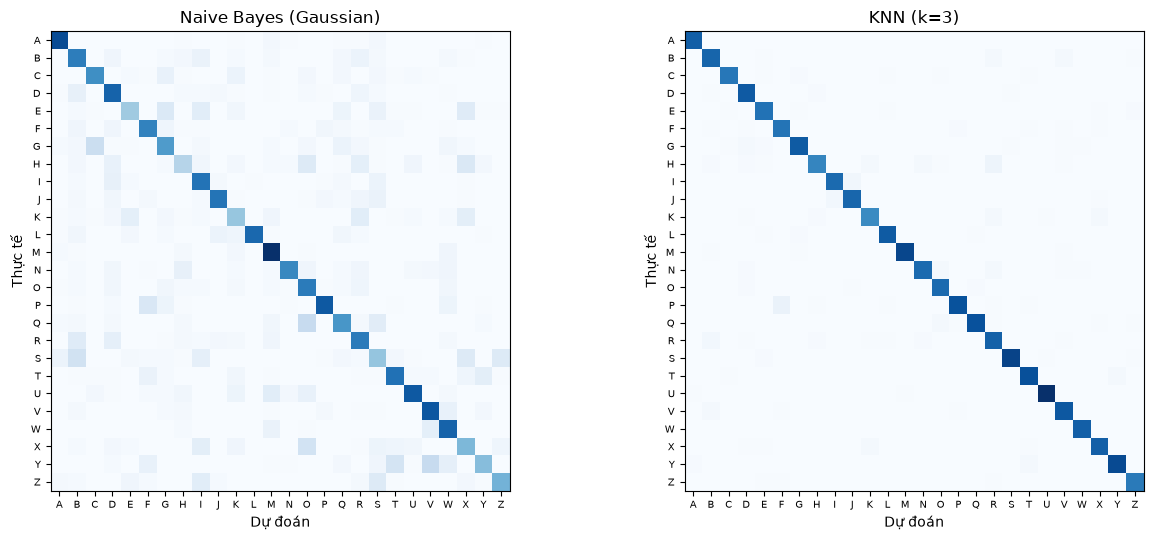


Naive Bayes (Gaussian) – cặp nhầm lẫn nhiều nhất (thật -> dự đoán):
  Q -> O: 37 lần
  Y -> V: 37 lần
  G -> C: 34 lần
  S -> B: 29 lần
  X -> O: 28 lần
  Y -> T: 27 lần
  P -> F: 23 lần
  H -> X: 22 lần

KNN (k=3) – cặp nhầm lẫn nhiều nhất (thật -> dự đoán):
  P -> F: 12 lần
  H -> R: 9 lần
  I -> J: 6 lần
  R -> B: 5 lần
  J -> I: 5 lần
  K -> X: 4 lần
  B -> V: 4 lần
  Y -> T: 4 lần


In [18]:
def confusion_matrix(y_true, y_pred, n=26):
    cm = np.zeros((n, n), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)
    return cm

def top_confusions(cm, n=8):
    off = cm.copy(); np.fill_diagonal(off, 0)
    idx = np.dstack(np.unravel_index(np.argsort(-off, axis=None)[:n], off.shape))[0]
    return [(chr(65+i), chr(65+j), off[i, j]) for i, j in idx]

best_name = max(results, key=lambda n: results[n][0])
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, name in zip(axes, ["Naive Bayes (Gaussian)", best_name]):
    cm = confusion_matrix(yte, results[name][1])
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(26)); ax.set_xticklabels([chr(65+i) for i in range(26)], fontsize=7)
    ax.set_yticks(range(26)); ax.set_yticklabels([chr(65+i) for i in range(26)], fontsize=7)
    ax.set_xlabel("Dự đoán"); ax.set_ylabel("Thực tế"); ax.set_title(name)
plt.tight_layout(); plt.show()

for name in ["Naive Bayes (Gaussian)", best_name]:
    print(f"\n{name} – cặp nhầm lẫn nhiều nhất (thật -> dự đoán):")
    for a, b, c in top_confusions(confusion_matrix(yte, results[name][1])):
        print(f"  {a} -> {b}: {c} lần")

In [19]:
cm = confusion_matrix(yte, results[best_name][1])
print(f"Precision / Recall theo lớp – {best_name}")
for i in range(26):
    tp = cm[i, i]
    print(f"  {chr(65+i)}: P={tp/cm[:, i].sum():.3f}  R={tp/cm[i].sum():.3f}")

Precision / Recall theo lớp – KNN (k=3)
  A: P=0.980  R=1.000
  B: P=0.917  R=0.941
  C: P=0.978  R=0.956
  D: P=0.921  R=0.974
  E: P=0.931  R=0.957
  F: P=0.905  R=0.950
  G: P=0.962  R=0.944
  H: P=0.945  R=0.840
  I: P=0.966  R=0.959
  J: P=0.953  R=0.960
  K: P=0.937  R=0.908
  L: P=0.974  R=0.974
  M: P=0.994  R=0.982
  N: P=0.966  R=0.927
  O: P=0.940  R=0.966
  P: P=0.975  R=0.908
  Q: P=0.981  R=0.952
  R: P=0.865  R=0.919
  S: P=0.988  R=0.977
  T: P=0.952  R=0.975
  U: P=0.989  R=0.989
  V: P=0.939  R=0.968
  W: P=0.987  R=1.000
  X: P=0.949  R=0.961
  Y: P=0.982  R=0.964
  Z: P=0.963  R=0.977


## 6. Nhận xét

- **KNN vượt trội Naive Bayes** (~95–96% so với ~62–72%).
- **Naive Bayes yếu** vì giả định độc lập không đúng: các đặc trưng (`x2bar`, `y2bar`, `xybar`, ...) đều là moment của cùng một ảnh nên tương quan mạnh. Gaussian còn sai thêm vì đặc trưng là số nguyên 0–15; biến thể Categorical tốt hơn khoảng 10 điểm phần trăm.
- **KNN** cho kết quả tốt nhất ở k nhỏ (1–5) và giảm dần khi k tăng; chuẩn hoá z-score không giúp ích vì các đặc trưng đã cùng thang 0–15.
- **Lỗi còn lại** tập trung ở các cặp chữ có hình dạng gần nhau (F↔P, J→I, E→Z, H→K).
- **Chi phí:** Naive Bayes train/dự đoán rất nhanh; KNN phải so với toàn bộ tập train cho mỗi mẫu test.